# Tugas Praktikum 4: Association Rule

## 0. Import library

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from mlxtend.frequent_patterns import fpgrowth, association_rules

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

## 1. Import Dataset

In [36]:
DATA_PATH = "Online Retail.xlsx"
df_raw = pd.read_excel(DATA_PATH)

display(df_raw.head())
print("Dimensi dataset:", df_raw.shape)
df_raw.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Dimensi dataset: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 2. EDA

In [37]:
missing_summary = df_raw.isna().sum().rename("Missing Value").to_frame()
display(missing_summary)
print("Jumlah invoice unik sebelum cleaning:", df_raw["InvoiceNo"].nunique())
print("Jumlah baris dengan InvoiceNo diawali 'C':", df_raw["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Jumlah baris dengan Quantity <= 0:", (df_raw["Quantity"] <= 0).sum())

,Missing Value
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Jumlah invoice unik sebelum cleaning: 25900
Jumlah baris dengan InvoiceNo diawali 'C': 9288
Jumlah baris dengan Quantity <= 0: 10624


## 3. Data Cleaning

1. Hapus baris dengan `Description` kosong.
2. Hapus transaksi yang dibatalkan (`InvoiceNo` yang diawali huruf `C`).
3. Hapus baris dengan `Quantity <= 0`.

In [38]:
rows_before = len(df_raw)
invoices_before = df_raw["InvoiceNo"].nunique()

df_clean = df_raw.dropna(subset=["Description"]).copy()
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)
df_clean = df_clean[~df_clean["InvoiceNo"].str.startswith("C")].copy()
df_clean = df_clean[df_clean["Quantity"] > 0].copy()

rows_after = len(df_clean)
invoices_after = df_clean["InvoiceNo"].nunique()

cleaning_summary = pd.DataFrame({
    "Kondisi": ["Sebelum pembersihan", "Sesudah pembersihan", "Baris yang dihapus"],
    "Jumlah baris": [rows_before, rows_after, rows_before - rows_after],
    "Jumlah invoice unik": [invoices_before, invoices_after, invoices_before - invoices_after]
})
display(cleaning_summary)
print("Jumlah Description unik setelah pembersihan:", df_clean["Description"].nunique())

,Kondisi,Jumlah baris,Jumlah invoice unik
0,Sebelum pembersihan,541909,25900
1,Sesudah pembersihan,530693,20136
2,Baris yang dihapus,11216,5764


Jumlah Description unik setelah pembersihan: 4077


## 4. Persiapan Data

In [39]:
# Ubah invoice dan produk menjadi indeks numerik, lalu bentuk matriks sparse.
invoice_codes, invoice_labels = pd.factorize(df_clean["InvoiceNo"], sort=False)
product_codes, product_labels = pd.factorize(df_clean["Description"], sort=False)

basket_matrix = coo_matrix(
    (np.ones(len(df_clean), dtype=np.int8), (invoice_codes, product_codes)),
    shape=(len(invoice_labels), len(product_labels))
).tocsr()
basket_matrix.sum_duplicates()
basket_matrix.data[:] = 1
basket_matrix = basket_matrix.astype(bool)

basket = pd.DataFrame.sparse.from_spmatrix(
    basket_matrix,
    index=invoice_labels,
    columns=product_labels
)

n_transactions, n_products = basket.shape
basket_density = basket_matrix.nnz / (n_transactions * n_products)
print(f"Dimensi basket: {basket.shape[0]:,} invoice x {basket.shape[1]:,} produk")
print(f"Jumlah kehadiran produk pada basket: {basket_matrix.nnz:,}")
print(f"Kepadatan basket: {basket_density:.4%}")

# Tampilkan sebagian basket dengan produk yang paling sering muncul.
product_counts = np.asarray(basket_matrix.sum(axis=0)).ravel()
top_product_positions = np.argsort(product_counts)[::-1][:8]
top_product_names = [product_labels[i] for i in top_product_positions]
basket_preview = basket.loc[:, top_product_names].head().sparse.to_dense()
display(basket_preview)

Dimensi basket: 20,136 invoice x 4,077 produk
Jumlah kehadiran produk pada basket: 519,974
Kepadatan basket: 0.6334%


,WHITE HANGING HEART T-LIGHT HOLDER,JUMBO BAG RED RETROSPOT,REGENCY CAKESTAND 3 TIER,PARTY BUNTING,LUNCH BAG RED RETROSPOT,ASSORTED COLOUR BIRD ORNAMENT,SET OF 3 CAKE TINS PANTRY DESIGN,PACK OF 72 RETROSPOT CAKE CASES
536365,True,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,True,False,False
536368,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False


## 5. Penerapan Algoritma

In [40]:
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.5

frequent_itemsets = fpgrowth(
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

frequent_itemsets["itemset_length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets_sorted = frequent_itemsets.sort_values(
    ["support", "itemset_length"], ascending=[False, True]
).reset_index(drop=True)

print(f"Minimum support: {MIN_SUPPORT:.0%}")
print("Jumlah frequent itemsets:", len(frequent_itemsets))
print("Jumlah transaksi yang dianalisis:", n_transactions)

def itemset_to_text(itemset):
    return "{ " + ", ".join(sorted(map(str, itemset))) + " }"

itemsets_preview = frequent_itemsets_sorted[["itemsets", "support", "itemset_length"]].head(15).copy()
itemsets_preview["itemsets"] = itemsets_preview["itemsets"].apply(itemset_to_text)
display(itemsets_preview.round({"support": 4}))

Minimum support: 1%
Jumlah frequent itemsets: 1854
Jumlah transaksi yang dianalisis: 20136


,itemsets,support,itemset_length
0,{ WHITE HANGING HEART T-LIGHT HOLDER },0.1122,1
1,{ JUMBO BAG RED RETROSPOT },0.1039,1
2,{ REGENCY CAKESTAND 3 TIER },0.0988,1
3,{ PARTY BUNTING },0.0837,1
4,{ LUNCH BAG RED RETROSPOT },0.0777,1
5,{ ASSORTED COLOUR BIRD ORNAMENT },0.0723,1
6,{ SET OF 3 CAKE TINS PANTRY DESIGN },0.0688,1
7,{ PACK OF 72 RETROSPOT CAKE CASES },0.0656,1
8,{ LUNCH BAG BLACK SKULL. },0.0632,1
9,{ NATURAL SLATE HEART CHALKBOARD },0.0620,1


## 6. Evaluasi aturan asosiasi

In [44]:
rules = association_rules(
    frequent_itemsets.drop(columns=["itemset_length"], errors="ignore"),
    metric="confidence",
    min_threshold=MIN_CONFIDENCE
)

# Urutkan aturan berdasarkan lift, confidence, dan support.
# Pembulatan lift digunakan untuk menangani perbedaan floating-point.
rules_sorted = (
    rules.assign(lift_sort=rules["lift"].round(10))
    .sort_values(
        ["lift_sort", "confidence", "support"],
        ascending=[False, False, False],
        kind="mergesort"
    )
    .drop(columns="lift_sort")
    .reset_index(drop=True)
)

print(f"Minimum confidence: {MIN_CONFIDENCE:.0%}")
print("Jumlah aturan asosiasi yang memenuhi ambang:", len(rules_sorted))

# Format tabel aturan asosiasi
rules_display = rules_sorted[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].copy()

rules_display["antecedents"] = rules_display["antecedents"].apply(itemset_to_text)
rules_display["consequents"] = rules_display["consequents"].apply(itemset_to_text)

# Tampilkan seluruh aturan asosiasi
with pd.option_context("display.max_rows", None):
    display(
        rules_display.head(20).round({
            "support": 5,
            "confidence": 4,
            "lift": 4
        })
    )

Minimum confidence: 50%
Jumlah aturan asosiasi yang memenuhi ambang: 841


,antecedents,consequents,support,confidence,lift
0,"{ HERB MARKER PARSLEY, HERB MARKER ROSEMARY }",{ HERB MARKER THYME },0.01008,0.9442,80.2200
1,{ HERB MARKER THYME },"{ HERB MARKER PARSLEY, HERB MARKER ROSEMARY }",0.01008,0.8565,80.2200
2,"{ HERB MARKER PARSLEY, HERB MARKER THYME }",{ HERB MARKER ROSEMARY },0.01008,0.9531,79.9610
3,{ HERB MARKER ROSEMARY },"{ HERB MARKER PARSLEY, HERB MARKER THYME }",0.01008,0.8458,79.9610
4,{ HERB MARKER THYME },{ HERB MARKER ROSEMARY },0.01098,0.9325,78.2359
5,{ HERB MARKER ROSEMARY },{ HERB MARKER THYME },0.01098,0.9208,78.2359
6,"{ HERB MARKER ROSEMARY, HERB MARKER THYME }",{ HERB MARKER PARSLEY },0.01008,0.9186,77.7141
7,{ HERB MARKER PARSLEY },"{ HERB MARKER ROSEMARY, HERB MARKER THYME }",0.01008,0.8529,77.7141
8,{ HERB MARKER THYME },{ HERB MARKER PARSLEY },0.01058,0.8987,76.0374
9,{ HERB MARKER PARSLEY },{ HERB MARKER THYME },0.01058,0.8950,76.0374


### 10 produk dengan support tertinggi

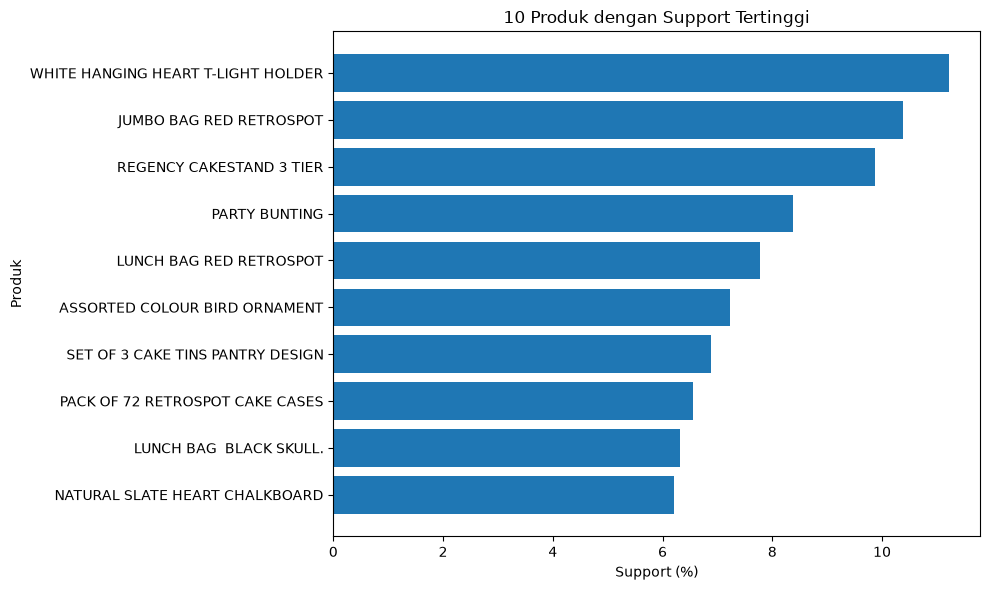

In [42]:
single_itemsets = frequent_itemsets[frequent_itemsets["itemset_length"] == 1].copy()
single_itemsets["product"] = single_itemsets["itemsets"].apply(lambda x: next(iter(x)))
top10_products = single_itemsets.sort_values("support", ascending=False).head(10).copy()

top10_products_plot = top10_products.sort_values("support", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(top10_products_plot["product"].str.strip(), top10_products_plot["support"] * 100)
plt.xlabel("Support (%)")
plt.ylabel("Produk")
plt.title("10 Produk dengan Support Tertinggi")
plt.tight_layout()
plt.show()

## 7. Tiga aturan terbaik berdasarkan lift

Lift mengukur seberapa besar kemunculan antecedent dan consequent secara bersama dibandingkan dengan kondisi independen. `lift > 1` menunjukkan asosiasi positif. Semakin besar nilainya, semakin kuat asosiasi relatif terhadap frekuensi dasar consequent.

In [43]:
top3_rules = rules_sorted.head(3).copy()
top3_display = top3_rules[["antecedents", "consequents", "support", "confidence", "lift"]].copy()
top3_display["antecedents"] = top3_display["antecedents"].apply(itemset_to_text)
top3_display["consequents"] = top3_display["consequents"].apply(itemset_to_text)
top3_display["jumlah invoice"] = (top3_display["support"] * n_transactions).round().astype(int)
display(top3_display[["antecedents", "consequents", "support", "confidence", "lift", "jumlah invoice"]].round({"support": 5, "confidence": 4, "lift": 2}))

,antecedents,consequents,support,confidence,lift,jumlah invoice
0,"{ HERB MARKER PARSLEY, HERB MARKER ROSEMARY }",{ HERB MARKER THYME },0.01008,0.9442,80.22,203
1,{ HERB MARKER THYME },"{ HERB MARKER PARSLEY, HERB MARKER ROSEMARY }",0.01008,0.8565,80.22,203
2,"{ HERB MARKER PARSLEY, HERB MARKER THYME }",{ HERB MARKER ROSEMARY },0.01008,0.9531,79.96,203



### Interpretasi Bisnis

Berdasarkan hasil pengurutan association rules menggunakan nilai lift tertinggi, diperoleh tiga aturan asosiasi terbaik sebagai berikut.

1. **HERB MARKER PARSLEY dan HERB MARKER ROSEMARY → HERB MARKER THYME**

   Aturan ini memiliki support sekitar **1,008%** (203 invoice), confidence **94,42%**, dan lift **80,22**. Artinya, dari seluruh invoice yang membeli HERB MARKER PARSLEY dan HERB MARKER ROSEMARY secara bersamaan, sekitar 94,42% juga membeli HERB MARKER THYME. Nilai lift yang sangat tinggi menunjukkan bahwa ketiga produk memiliki hubungan pembelian yang kuat.

2. **HERB MARKER THYME → HERB MARKER PARSLEY dan HERB MARKER ROSEMARY**

   Aturan ini memiliki support sekitar **1,008%** (203 invoice), confidence **85,65%**, dan lift **80,22**. Artinya, dari seluruh invoice yang membeli HERB MARKER THYME, sekitar 85,65% juga membeli HERB MARKER PARSLEY dan HERB MARKER ROSEMARY secara bersamaan. Hal ini menunjukkan bahwa HERB MARKER THYME memiliki keterkaitan pembelian yang kuat dengan kedua produk tersebut.

3. **HERB MARKER PARSLEY dan HERB MARKER THYME → HERB MARKER ROSEMARY**

   Aturan ini memiliki support sekitar **1,008%** (203 invoice), confidence **95,31%**, dan lift **79,96**. Artinya, dari seluruh invoice yang membeli HERB MARKER PARSLEY dan HERB MARKER THYME secara bersamaan, sekitar 95,31% juga membeli HERB MARKER ROSEMARY.

**Analisis Bisnis:**

Ketiga aturan tersebut menunjukkan adanya kelompok produk HERB MARKER PARSLEY, HERB MARKER ROSEMARY, dan HERB MARKER THYME yang memiliki keterkaitan pembelian sangat kuat.

Dalam konteks bisnis ritel, informasi ini dapat dimanfaatkan untuk:
- Menempatkan ketiga produk berdekatan agar memudahkan pelanggan menemukan produk yang saling berkaitan.
- Membuat rekomendasi produk pelengkap berdasarkan riwayat pembelian pelanggan.
- Menawarkan paket bundling ketiga produk untuk meningkatkan peluang pembelian bersama.

Meskipun memiliki nilai lift yang sangat tinggi, support ketiga aturan hanya sekitar 1,008%. Artinya, pola tersebut ditemukan pada sebagian kecil dari keseluruhan invoice. Oleh karena itu, strategi bisnis tetap perlu mempertimbangkan potensi pasar dan jumlah transaksi yang terlibat.